# Лабораторная работа №6. Исследование параметров text-to-image генерации

**Выполнил:** Котов Дэвид Арсенович  
**Группа:**  
**Проверил:**  
**Дисциплина:** «Искусственный интеллект в креативных технологиях»

**Вариант 27:** 27 = (5 − 1)·6 + 3. Бриф 5 — обложка электронного релиза: металл с радужными бликами, макросъёмка. Фактор 3 — **512×512 → 768×768**, выход за рекомендованный размер SD Turbo.

Серия seed **101–105**; меняется только размер. В обоих режимах запрос английский, один шаг, guidance_scale=0.0, свежий генератор CPU, модель на GPU во float16.

| Модель | Полная ревизия |
| --- | --- |
| stabilityai/sd-turbo | b261bac6fd2cf515557d5d0707481eafa0485ec2 |
| openai/clip-vit-base-patch32 | 3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268 |

CLIP считается относительно исходного английского брифа. Рост детализации или контраста не означает улучшение качества; признаки артефактов и узнаваемость металлической поверхности оцениваются визуально отдельно.

SD Turbo: [лицензия закреплённой ревизии](https://huggingface.co/stabilityai/sd-turbo/blob/b261bac6fd2cf515557d5d0707481eafa0485ec2/LICENSE.md), учебное некоммерческое использование, действует Acceptable Use Policy. Для CLIP [официальный репозиторий](https://github.com/openai/CLIP/blob/main/LICENSE) публикует MIT; карточка конкретного снимка — [на Hugging Face](https://huggingface.co/openai/clip-vit-base-patch32/blob/3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268/README.md). Лицензии моделей отделены от лицензии собственного кода.

Powered by Stability AI.


## 1. Подготовка среды

Google Colab с GPU T4; отдельный блокнот ЛР6. Используются те же версии diffusers и transformers, что в ЛР5. Предустановленный torch не заменяется. При отсутствии CUDA расчёт останавливается, чтобы не подменять измерение времени другой платформой.


In [1]:
import os, sys, time, shutil, pathlib, platform, importlib, subprocess
from importlib.metadata import version as pkg_version, PackageNotFoundError

T_START = time.perf_counter()
WORK = pathlib.Path.cwd()
if WORK.name != "LR06":
    WORK = WORK / "LR06"
WORK.mkdir(parents=True, exist_ok=True)
os.chdir(WORK)
if str(WORK) not in sys.path:
    sys.path.insert(0, str(WORK))
print("Рабочая папка: LR06")

import torch
if not torch.cuda.is_available():
    raise SystemExit("Для ЛР6 нужна CUDA. Выберите GPU T4 и запустите ноутбук заново.")

PINS = {"diffusers": "0.40.0", "transformers": "5.16.1"}
def installed_version(pkg):
    try:
        return pkg_version(pkg)
    except PackageNotFoundError:
        return None

todo = [f"{k}=={v}" for k, v in PINS.items() if installed_version(k) != v]
todo += [p for p in ("accelerate", "safetensors", "Pillow", "scipy") if installed_version(p) is None]
if todo:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *todo], check=True)
    importlib.invalidate_caches()
    if any(m in sys.modules for m in PINS):
        raise SystemExit("Пакеты обновлены. Перезапустите сеанс и выполните ноутбук с начала.")
print("Установлены версии:", {p: installed_version(p) for p in PINS})

ART = WORK / "artifacts"
ART.mkdir(exist_ok=True)


Рабочая папка: LR06
Установлены версии: {'diffusers': '0.40.0', 'transformers': '5.16.1'}


Фиксируется фактическая среда: версии, GPU, CUDA, cuDNN и драйвер. Эти сведения затем входят в манифесты изображений и итоговый JSON.


In [2]:
import numpy as np
import scipy
import torch, diffusers, transformers, PIL

CUDA = torch.cuda.is_available()
DEVICE_NAME = torch.cuda.get_device_name(0)
driver = subprocess.run(["nvidia-smi", "--query-gpu=driver_version", "--format=csv,noheader"],
                        capture_output=True, text=True)
ENV = dict(python=sys.version.split()[0], platform=platform.platform(), device=DEVICE_NAME,
           cuda=torch.version.cuda, cudnn=torch.backends.cudnn.version(),
           driver=driver.stdout.strip() if driver.returncode == 0 else None,
           gpu_memory_gib=round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 1),
           packages={p: pkg_version(p) for p in ("torch", "diffusers", "transformers", "Pillow", "numpy", "accelerate", "safetensors", "scipy")})
for key, value in ENV.items():
    print(key, "=", value)


python = 3.13.16
platform = Linux-6.6.159+-x86_64-with-glibc2.39
device = Tesla T4
cuda = 13.0
cudnn = 92700
driver = 580.82.07
gpu_memory_gib = 14.6
packages = {'torch': '2.11.0+cu130', 'diffusers': '0.40.0', 'transformers': '5.16.1', 'Pillow': '11.3.0', 'numpy': '2.1.3', 'accelerate': '1.15.0', 'safetensors': '0.8.0', 'scipy': '1.16.3'}


## 2. Учебные библиотеки

Оба файла записываются ячейками writefile без изменения текста. Их размер и SHA-256 сверяются до расчёта.


In [3]:
%%writefile lab05_lib.py
# ЛР 5. Запуск открытой модели text-to-image. Библиотека учебных функций.
# Проверено 19.09.2026: Google Colab, GPU T4, Python 3.13, torch 2.11.0+cu128, diffusers 0.40.0, transformers 5.16.1.
# Модель: stabilityai/sd-turbo, ревизия закреплена (см. REVISION). Веса загружаются с Hugging Face без авторизации.
import hashlib, io, time
import numpy as np
import torch
from PIL import Image
from diffusers import AutoPipelineForText2Image
from diffusers.utils import logging as dlog

dlog.set_verbosity_error()  # убирает предупреждения о приведении типов при pipe.to(dtype)

MODEL_ID = "stabilityai/sd-turbo"
REVISION = "b261bac6fd2cf515557d5d0707481eafa0485ec2"

# Пять контекстов (брифов). Во всех запретены текст, логотипы и люди.
BRIEFS = [
    "editorial poster concept for a robotics festival, glowing mechanical arm silhouette, deep blue and amber palette, clean composition, no text, no logo, no people",
    "square podcast cover about the city environment, abstract layered skyline of geometric shapes, teal and orange palette, minimal flat style, no text, no people",
    "poster concept for a science exhibition, abstract constellation of connected nodes, dark background with white and cyan lines, balanced composition, no text, no logo",
    "visual for an ecology lecture series, stylized forest canopy seen from above, layered green shapes, soft morning light, no text, no people",
    "cover art for an electronic music release, brushed metal surface with iridescent reflections, macro photography style, strong contrast, no text, no logo, no people",
]


def load_pipe(dtype=torch.float16):
    """Загружает закреплённую ревизию (файлы fp16) на GPU; dtype задаёт тип вычислений."""
    pipe = AutoPipelineForText2Image.from_pretrained(
        MODEL_ID, revision=REVISION, torch_dtype=torch.float16, variant="fp16", use_safetensors=True)
    pipe.set_progress_bar_config(disable=True)
    return pipe.to("cuda", dtype)


def generate(pipe, prompt, seed, steps=1, guidance=0.0, size=512, batch=1, gen_device="cpu"):
    """Возвращает список PIL-изображений. Для каждого элемента пакета свой генератор: seed, seed+1, ..."""
    gens = [torch.Generator(device=gen_device).manual_seed(seed + i) for i in range(batch)]
    return pipe(prompt=[prompt] * batch, num_inference_steps=steps, guidance_scale=guidance,
                height=size, width=size, generator=gens).images


def generate_fixed_noise(pipe, prompt, seed, steps=1, guidance=0.0, size=512):
    """Начальный шум всегда строится в float32 и приводится к типу вычислений: так меняется только точность."""
    g = torch.Generator(device="cpu").manual_seed(seed)
    lat = torch.randn((1, 4, size // 8, size // 8), generator=g, dtype=torch.float32).to("cuda", pipe.unet.dtype)
    return pipe(prompt=[prompt], num_inference_steps=steps, guidance_scale=guidance, height=size, width=size, latents=lat).images[0]


def png_bytes(img):
    buf = io.BytesIO()
    img.save(buf, format="PNG")
    return buf.getvalue()


def sha(data):
    return hashlib.sha256(data).hexdigest()


def to_arr(img):
    return np.asarray(img.convert("RGB"), dtype=np.float64)


def psnr_db(a, b):
    """PSNR для значений 0..255; inf, если изображения совпадают."""
    mse = np.mean((to_arr(a) - to_arr(b)) ** 2)
    return float("inf") if mse == 0 else 10 * np.log10(255.0 ** 2 / mse)


def max_abs_diff(a, b):
    return int(np.max(np.abs(to_arr(a) - to_arr(b))))


def jpeg_roundtrip(img, quality=90):
    buf = io.BytesIO()
    img.save(buf, format="JPEG", quality=quality)
    buf.seek(0)
    return Image.open(buf).convert("RGB"), buf.getvalue()


def classify(psnr, tol_db=40.0):
    """Классификация пары по допуску, заданному до эксперимента."""
    return "identical" if psnr == float("inf") else ("close" if psnr >= tol_db else "different")


# Шесть условий сравнения (фактор варианта). Каждое условие даёт пару изображений A и B.
CONDITIONS = ["repeat", "seed_plus_1", "generator_device", "dtype", "file_format", "batch"]


def make_pair(pipe, prompt, seed, cond):
    if cond == "repeat":
        a = generate(pipe, prompt, seed)[0]; b = generate(pipe, prompt, seed)[0]
    elif cond == "seed_plus_1":
        a = generate(pipe, prompt, seed)[0]; b = generate(pipe, prompt, seed + 1)[0]
    elif cond == "generator_device":
        a = generate(pipe, prompt, seed, gen_device="cpu")[0]; b = generate(pipe, prompt, seed, gen_device="cuda")[0]
    elif cond == "dtype":
        pipe.to(torch.float16); a = generate(pipe, prompt, seed)[0]
        pipe.to(torch.float32); b = generate(pipe, prompt, seed)[0]
        pipe.to(torch.float16)
    elif cond == "file_format":
        a = generate(pipe, prompt, seed)[0]; b, _ = jpeg_roundtrip(a, 90)
    elif cond == "batch":
        a = generate(pipe, prompt, seed)[0]; b = generate(pipe, prompt, seed, batch=4)[0]
    else:
        raise ValueError(cond)
    return a, b


def variant_summary(pipe, n):
    """Вариант n = 1..30: контекст c = (n-1)//6 + 1, условие k = (n-1)%6 + 1."""
    c, k = (n - 1) // 6, (n - 1) % 6
    seed = 1000 + n
    t0 = time.perf_counter()
    a, b = make_pair(pipe, BRIEFS[c], seed, CONDITIONS[k])
    dt = time.perf_counter() - t0
    p = psnr_db(a, b)
    pf = None
    if CONDITIONS[k] == "dtype":  # проверка причины: одинаковый начальный шум в обоих режимах
        pipe.to(torch.float16); fa = generate_fixed_noise(pipe, BRIEFS[c], seed)
        pipe.to(torch.float32); fb = generate_fixed_noise(pipe, BRIEFS[c], seed)
        pipe.to(torch.float16); pf = psnr_db(fa, fb)
    return dict(variant=n, ctx=c + 1, cond=CONDITIONS[k], seed=seed, sha_a=sha(png_bytes(a)), sha_b=sha(png_bytes(b)),
                pixel_equal=bool(np.array_equal(to_arr(a), to_arr(b))), max_diff=max_abs_diff(a, b), psnr=p,
                verdict=classify(p), seconds=round(dt, 2), psnr_fixed_noise=pf)


Writing lab05_lib.py


Ячейка 2 — `lab06_lib.py`:

In [4]:
%%writefile lab06_lib.py
# ЛР 6. Исследование параметров text-to-image генерации. Библиотека учебных функций.
# Требуется файл lab05_lib.py из ЛР 5 в той же папке (из него берутся модель, генерация и брифы).
# Проверено 19.09.2026: Google Colab, GPU T4, Python 3.13, torch 2.11.0+cu128, diffusers 0.40.0, transformers 5.16.1.
import time
import numpy as np
import torch
from scipy import ndimage
from transformers import CLIPModel, CLIPProcessor
import lab05_lib as L

CLIP_ID = "openai/clip-vit-base-patch32"
CLIP_REVISION = "3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268"
SEEDS = range(101, 106)

# Короткие запросы (только предмет) и русские переводы брифов из ЛР 5.
SHORT = ["robotic arm poster", "podcast cover about the city", "science exhibition poster",
         "ecology lecture visual, forest", "electronic music cover art"]
RU = [
    "плакат-концепт для фестиваля робототехники, светящийся силуэт механической руки, глубокий синий и янтарный цвета, чистая композиция, без текста, без логотипа, без людей",
    "квадратная обложка подкаста о городской среде, абстрактный многослойный горизонт из геометрических фигур, бирюзовый и оранжевый цвета, минималистичный плоский стиль, без текста, без людей",
    "плакат-концепт научной выставки, абстрактное созвездие соединённых узлов, тёмный фон с белыми и голубыми линиями, сбалансированная композиция, без текста, без логотипа",
    "визуал для цикла лекций по экологии, стилизованный полог леса сверху, многослойные зелёные формы, мягкий утренний свет, без текста, без людей",
    "обложка электронного музыкального релиза, шлифованная металлическая поверхность с радужными бликами, стиль макросъёмки, сильный контраст, без текста, без логотипа, без людей",
]

# Шесть факторов: (имя, изменение A -> B). Базовый режим: структурированный английский запрос, 512, 1 шаг, guidance 0.
FACTORS = ["steps_1_to_4", "size_512_to_384", "size_512_to_768", "prompt_short_to_structured", "guidance_0_to_3", "language_en_to_ru"]


def load_clip():
    model = CLIPModel.from_pretrained(CLIP_ID, revision=CLIP_REVISION).to("cuda").eval()
    proc = CLIPProcessor.from_pretrained(CLIP_ID, revision=CLIP_REVISION)
    return model, proc


@torch.no_grad()
def clip_sim(clip, img, text):
    """Косинусное сходство изображения и текста в CLIP, умноженное на 100 (не CLIPScore)."""
    model, proc = clip
    inp = proc(text=[text], images=img, return_tensors="pt", padding=True, truncation=True).to("cuda")
    out = model(**inp)
    a = out.image_embeds / out.image_embeds.norm(dim=-1, keepdim=True)
    b = out.text_embeds / out.text_embeds.norm(dim=-1, keepdim=True)
    return float((a * b).sum()) * 100


def luma(img):
    x = np.asarray(img.convert("RGB"), dtype=np.float64) / 255
    return 0.299 * x[..., 0] + 0.587 * x[..., 1] + 0.114 * x[..., 2]


def edge_energy(img):
    """Средняя длина градиента яркости (оператор Собеля, нормировка 1/8), как в ЛР 4."""
    y = luma(img)
    return float(np.mean(np.hypot(ndimage.sobel(y, axis=0), ndimage.sobel(y, axis=1)) / 8))


def contrast(img):
    return float(np.std(luma(img)))


def settings(factor, c):
    """Пара режимов (A, B) для контекста c = 0..4: словарь параметров generate() плюс текст запроса."""
    base = dict(prompt=L.BRIEFS[c], steps=1, guidance=0.0, size=512)
    a, b = dict(base), dict(base)
    if factor == "steps_1_to_4":
        b["steps"] = 4
    elif factor == "size_512_to_384":
        b["size"] = 384
    elif factor == "size_512_to_768":
        b["size"] = 768
    elif factor == "prompt_short_to_structured":
        a["prompt"] = SHORT[c]
    elif factor == "guidance_0_to_3":
        b["guidance"] = 3.0
    elif factor == "language_en_to_ru":
        b["prompt"] = RU[c]
    else:
        raise ValueError(factor)
    return a, b


def measure(pipe, clip, cfg, c, seed):
    """Одно изображение: метрики и время генерации, с; сходство CLIP считается с исходным английским брифом."""
    t0 = time.perf_counter()
    img = L.generate(pipe, cfg["prompt"], seed, steps=cfg["steps"], guidance=cfg["guidance"], size=cfg["size"])[0]
    dt = time.perf_counter() - t0
    return dict(clip=clip_sim(clip, img, L.BRIEFS[c]), edge=edge_energy(img), contrast=contrast(img), seconds=dt), img


def variant_summary(pipe, clip, n, seeds=SEEDS):
    """Вариант n = 1..30: контекст c = (n-1)//6, фактор k = (n-1)%6. Для каждой метрики: A, s, B, разность, |d|/s, признак |d| > 2s."""
    c, k = (n - 1) // 6, (n - 1) % 6
    a_cfg, b_cfg = settings(FACTORS[k], c)
    A = {m: [] for m in ("clip", "edge", "contrast", "seconds")}
    B = {m: [] for m in A}
    for cfg in (a_cfg, b_cfg):  # прогрев: первый вызов с новым размером и числом шагов медленнее
        L.generate(pipe, cfg["prompt"], 0, steps=cfg["steps"], guidance=cfg["guidance"], size=cfg["size"])
    for s in seeds:
        ma, _ = measure(pipe, clip, a_cfg, c, s)
        mb, _ = measure(pipe, clip, b_cfg, c, s)
        for m in A:
            A[m].append(ma[m]); B[m].append(mb[m])
    rows = []
    for m in A:
        d = np.mean(B[m]) - np.mean(A[m]); sa = np.std(A[m], ddof=1)
        rows.append((m, float(np.mean(A[m])), float(sa), float(np.mean(B[m])), float(d), float(abs(d) / sa) if sa > 0 else float("inf"), bool(abs(d) > 2 * sa)))
    return dict(variant=n, ctx=c + 1, factor=FACTORS[k], rows=rows)


Writing lab06_lib.py


Проверяются lab05_lib.py — 6447 байт, SHA-256 4eb17650…; lab06_lib.py — 6580 байт, SHA-256 c6d8473c….


In [5]:
import hashlib

EXPECTED = {"lab05_lib.py": (6447, "4eb176506585ffcda1702605a767309fb451808229c3622f80ce882b7fa2ce1a"), "lab06_lib.py": (6580, "c6d8473cf5a3000f4c27fbdef57916c2fbce347db272928d5c4729472f748bd8")}
LIB_SHA = {}
for name, (size, prefix) in EXPECTED.items():
    data = (WORK / name).read_bytes()
    h = hashlib.sha256(data).hexdigest()
    LIB_SHA[name] = dict(bytes=len(data), sha256=h, matches_methodical=(len(data) == size and h.startswith(prefix)))
    print(f"{name}: {len(data)} байт, SHA-256 {h}")
    print(f"   ожидалось {size} байт, {prefix}… -> {'совпадает' if LIB_SHA[name]['matches_methodical'] else 'НЕ СОВПАДАЕТ'}")
assert all(v["matches_methodical"] for v in LIB_SHA.values()), "текст библиотек отличается от выданного"


lab05_lib.py: 6447 байт, SHA-256 4eb176506585ffcda1702605a767309fb451808229c3622f80ce882b7fa2ce1a
   ожидалось 6447 байт, 4eb176506585ffcda1702605a767309fb451808229c3622f80ce882b7fa2ce1a… -> совпадает
lab06_lib.py: 6580 байт, SHA-256 c6d8473cf5a3000f4c27fbdef57916c2fbce347db272928d5c4729472f748bd8
   ожидалось 6580 байт, c6d8473cf5a3000f4c27fbdef57916c2fbce347db272928d5c4729472f748bd8… -> совпадает


## 3. Импорт библиотек

CUDA обязательна. Обе учебные библиотеки выполняются без изменений.


In [6]:
for name in ("lab05_lib", "lab06_lib"):
    sys.modules.pop(name, None)
import lab05_lib as L
import lab06_lib as M
assert M.L is L
print("Библиотеки подключены без изменений; GPU:", torch.cuda.get_device_name(0))


[transformers] `Siglip2ImageProcessorFast` is deprecated. The `Fast` suffix for image processors has been removed; use `Siglip2ImageProcessor` instead.


Библиотеки подключены без изменений; GPU: Tesla T4


## 4. Гипотеза и допуск до запуска

Исходная запись — в LR06/reports/journal.md. Меняется только размер: A — 512×512, B — 768×768. Латентная сетка увеличивается с 64×64 до 96×96; один seed при другой форме тензора не сохраняет композицию.

| Метрика | Ожидание |
| --- | --- |
| CLIP | изменение в пределах ±1,0, без устойчивого выигрыша от 768 |
| Энергия границ, исходный размер | снизится более чем на 10 %: градиент на пиксель зависит от масштаба |
| Энергия границ на общем масштабе 512 | останется в пределах ±10 %, если структура фактуры сохранится |
| Контраст | останется в пределах ±10 % |
| Время | вырастет более чем на 20 %; ожидается превышение 2s |

Практический допуск: CLIP ±1,0; энергия границ и контраст ±10 % от A; время ±20 % от A. Для CLIP больший отклик за допуском — улучшение соответствия тексту, меньший — ухудшение; для времени меньше — лучше. Для энергии границ и контраста выход в любую сторону за ±10 % обозначает ухудшение **близости к базовому виду**, а не художественного качества.

Ожидаются радужная фактура и возможные повторяющиеся структуры, разрывы или изменение композиции в 768. Их наличие проверяется по оригиналам всех seed; отсутствие артефактов также является результатом. Увеличение размера само по себе не считается улучшением.


In [7]:
TOL = {"clip": ("abs", 1.0), "edge": ("rel", 0.10), "contrast": ("rel", 0.10), "seconds": ("rel", 0.20)}
DIRECTION = {"clip": +1, "seconds": -1, "edge": 0, "contrast": 0}   # +1 больше = лучше, -1 меньше = лучше, 0 — важна близость к A
NAMES = {"clip": "сходство CLIP", "edge": "энергия границ", "contrast": "контраст", "seconds": "время, с"}
HYPOTHESIS = {"clip": "нейтрально", "edge": "снижение >10 % на исходном размере", "contrast": "нейтрально", "seconds": "ухудшение (рост >20 %)"}


def verdict(metric, a, d, scale=1.0):
    kind, tol = TOL[metric]
    tol = tol * scale * (abs(a) if kind == "rel" else 1.0)
    if abs(d) <= tol:
        return "нейтрально"
    if DIRECTION[metric] == 0:
        return "ухудшение"
    return "улучшение" if d * DIRECTION[metric] > 0 else "ухудшение"


for m in TOL:
    kind, tol = TOL[m]
    print(f"{NAMES[m]:15s} допуск {'±%.1f' % tol if kind == 'abs' else '±%d %% от A' % round(tol * 100)};  ожидание: {HYPOTHESIS[m]}")

сходство CLIP   допуск ±1.0;  ожидание: нейтрально
энергия границ  допуск ±10 % от A;  ожидание: снижение >10 % на исходном размере
контраст        допуск ±10 % от A;  ожидание: нейтрально
время, с        допуск ±20 % от A;  ожидание: ухудшение (рост >20 %)


## 5. Загрузка моделей

SD Turbo загружается по закреплённой ревизии, файлы fp16 и safetensors. CLIP загружается по своей полной ревизии; его оценка — косинусное сходство ×100, не CLIPScore.


In [8]:
t0 = time.perf_counter()
pipe = L.load_pipe()
t_pipe = time.perf_counter() - t0
t0 = time.perf_counter()
clip = M.load_clip()
t_clip = time.perf_counter() - t0
LOAD = dict(pipe_seconds=round(t_pipe, 1), clip_seconds=round(t_clip, 1), unet_dtype=str(pipe.unet.dtype),
            device=str(pipe.device), clip_device=str(next(clip[0].parameters()).device), model=L.MODEL_ID,
            model_revision=L.REVISION, clip_model=M.CLIP_ID, clip_revision=M.CLIP_REVISION)
for k, v in LOAD.items():
    print(f"{k:15s} {v}")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


model_index.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

... (10 outputs left out)

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

pipe_seconds    16.6
clip_seconds    12.8
unet_dtype      torch.float16
device          cuda:0
clip_device     cuda:0
model           stabilityai/sd-turbo
model_revision  b261bac6fd2cf515557d5d0707481eafa0485ec2
clip_model      openai/clip-vit-base-patch32
clip_revision   3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268


## 6. Режимы A и B

N=27: индекс брифа c=4, индекс фактора k=2. Словари M.settings различаются только полем size: 512 и 768. Генератор CPU одинакового seed применяется в обоих режимах.


In [9]:
N = 27
c, k = (N - 1) // 6, (N - 1) % 6
a_cfg, b_cfg = M.settings(M.FACTORS[k], c)
print("Вариант", N, "| бриф", c + 1, "| фактор", M.FACTORS[k])
print("A:", a_cfg)
print("B:", b_cfg)
diff = [key for key in a_cfg if a_cfg[key] != b_cfg[key]]
print("Различаются поля:", diff)
assert diff == ["size"], "изменено не ровно одно поле"
print("Сходство CLIP считается относительно брифа:", L.BRIEFS[c] == a_cfg["prompt"])
assert (c, k, M.FACTORS[k]) == (4, 2, "size_512_to_768")
assert (a_cfg["size"], b_cfg["size"]) == (512, 768)


Вариант 27 | бриф 5 | фактор size_512_to_768
A: {'prompt': 'cover art for an electronic music release, brushed metal surface with iridescent reflections, macro photography style, strong contrast, no text, no logo, no people', 'steps': 1, 'guidance': 0.0, 'size': 512}
B: {'prompt': 'cover art for an electronic music release, brushed metal surface with iridescent reflections, macro photography style, strong contrast, no text, no logo, no people', 'steps': 1, 'guidance': 0.0, 'size': 768}
Различаются поля: ['size']
Сходство CLIP считается относительно брифа: True


## 7. Серия seed 101–105

Функция M.variant_summary выполняет прогрев обоих режимов и десять измеряемых генераций. Временная обёртка measure_logged сохраняет полученные значения и изображения, не меняя вычисления; затем исходная M.measure восстанавливается.


In [10]:
RECORDS = []
_measure = M.measure


def measure_logged(pipe, clip, cfg, c, seed):
    met, img = _measure(pipe, clip, cfg, c, seed)
    RECORDS.append(dict(mode="A" if cfg == a_cfg else "B", seed=seed, size=cfg["size"], img=img,
                        png_sha256=L.sha(L.png_bytes(img)), **met))
    return met, img


M.measure = measure_logged
t0 = time.perf_counter()
try:
    res = M.variant_summary(pipe, clip, N)
finally:
    M.measure = _measure
t_series = time.perf_counter() - t0
print("Вариант", res["variant"], "| бриф", res["ctx"], "| фактор", res["factor"], f"| серия заняла {t_series:.1f} с")
for m, a, s, b, d, ratio, sig in res["rows"]:
    print(f"{m:9s} A={a:.4f} s={s:.4f} B={b:.4f} d={d:+.4f} |d|/s={ratio:.2f} 2s={'да' if sig else 'нет'}")

Вариант 27 | бриф 5 | фактор size_512_to_768 | серия заняла 13.4 с
clip      A=27.6343 s=1.0640 B=28.0588 d=+0.4245 |d|/s=0.40 2s=нет
edge      A=0.0353 s=0.0123 B=0.0305 d=-0.0048 |d|/s=0.39 2s=нет
contrast  A=0.1345 s=0.0199 B=0.1077 d=-0.0269 |d|/s=1.35 2s=нет
seconds   A=0.3070 s=0.0306 B=0.6593 d=+0.3523 |d|/s=11.52 2s=да


Пересчёт средних и выборочного s базы по зарегистрированным значениям проверяет согласованность сводки. Метрики вычисляются до уменьшения изображений для сравнительного листа.


In [11]:
import numpy as np

MET = ("clip", "edge", "contrast", "seconds")
per = {mode: {m: [r[m] for r in RECORDS if r["mode"] == mode] for m in MET} for mode in "AB"}
assert len(RECORDS) == 10 and [r["seed"] for r in RECORDS if r["mode"] == "A"] == list(M.SEEDS)
for m, a, s, b, d, ratio, sig in res["rows"]:
    assert np.isclose(a, np.mean(per["A"][m])) and np.isclose(b, np.mean(per["B"][m])) and np.isclose(s, np.std(per["A"][m], ddof=1))
print("Сводка variant_summary совпадает с пересчётом по записанным значениям\n")

print(f"{'seed':>4s} {'реж':>3s} {'размер':>7s} {'CLIP':>8s} {'границы':>8s} {'контраст':>8s} {'время, с':>9s}  SHA-256 PNG")
for r in sorted(RECORDS, key=lambda r: (r["mode"], r["seed"])):
    print(f"{r['seed']:4d} {r['mode']:>3s} {r['size']:5d}px {r['clip']:8.3f} {r['edge']:8.4f} {r['contrast']:8.4f} {r['seconds']:9.2f}  {r['png_sha256'][:16]}…")

Сводка variant_summary совпадает с пересчётом по записанным значениям

seed реж  размер     CLIP  границы контраст  время, с  SHA-256 PNG
 101   A   512px   26.846   0.0489   0.1377      0.29  d41f2c83f6c305e8…
 102   A   512px   26.337   0.0389   0.1658      0.36  0dd89d0891241593…
 103   A   512px   28.162   0.0431   0.1344      0.28  7a3e3832fee45d0f…
 104   A   512px   29.018   0.0270   0.1182      0.30  2953a430c9704890…
 105   A   512px   27.808   0.0186   0.1165      0.30  391cd5b78473ffa5…
 101   B   768px   27.800   0.0305   0.1004      0.67  dd073dfc424b5d8b…
 102   B   768px   29.418   0.0299   0.1231      0.67  a29ed70be528ba09…
 103   B   768px   28.398   0.0311   0.1110      0.65  f7aca1f0e1fae781…
 104   B   768px   25.509   0.0309   0.0916      0.66  1611ef79f4602ecd…
 105   B   768px   29.169   0.0304   0.1122      0.66  2214fdcb71b5411a…


### Сохранение исходных кадров

Все десять изображений сохраняются в родном разрешении с индивидуальными манифестами. Сохранение выполняется после измерения серии и не входит во время генерации. Они нужны для проверки артефактов, которые могут исчезнуть в уменьшенном листе.


In [12]:
from datetime import datetime, timezone
import json

for r in RECORDS:
    cfg = a_cfg if r["mode"] == "A" else b_cfg
    folder = ART / "series" / f"{r['mode']}_seed{r['seed']}"
    folder.mkdir(parents=True, exist_ok=True)
    data = L.png_bytes(r["img"])
    assert L.sha(data) == r["png_sha256"]
    (folder / "result.png").write_bytes(data)
    manifest = dict(model_id=L.MODEL_ID, revision=L.REVISION, prompt=cfg["prompt"], seed=r["seed"],
                    steps=cfg["steps"], guidance_scale=cfg["guidance"], size=cfg["size"], generator_device="cpu",
                    dtype=LOAD["unet_dtype"], device=ENV["device"], environment=ENV,
                    clip_model_id=M.CLIP_ID, clip_revision=M.CLIP_REVISION, clip_reference_prompt=L.BRIEFS[c],
                    image_size=list(r["img"].size), image_mode=r["img"].mode, sha256=r["png_sha256"],
                    library_sha256=LIB_SHA, condition=r["mode"], generation_seconds=r["seconds"],
                    metrics={key: r[key] for key in ("clip", "edge", "contrast")},
                    date_utc=datetime.now(timezone.utc).isoformat())
    (folder / "manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")
print("Сохранены 10 исходных изображений и их манифесты: LR06/artifacts/series/")


Сохранены 10 исходных изображений и их манифесты: LR06/artifacts/series/


Итоговая таблица разделяет четыре метрики, относительное изменение, учебный критерий 2s и практический допуск. Правило 2s не является формальным статистическим тестом.


In [13]:
ROWS = []
print(f"{'метрика':15s} {'A':>9s} {'s':>8s} {'B':>9s} {'Δ':>9s} {'Δ/A, %':>8s} {'|Δ|/s':>7s} {'|Δ|>2s':>7s}  по допуску")
for m, a, s, b, d, ratio, sig in res["rows"]:
    v = verdict(m, a, d)
    ROWS.append(dict(metric=m, A=a, s=s, B=b, delta=d, delta_rel_pct=100 * d / a, ratio=ratio, sig_2s=sig, verdict=v))
    print(f"{NAMES[m]:15s} {a:9.4f} {s:8.4f} {b:9.4f} {d:+9.4f} {100 * d / a:+8.1f} {ratio:7.2f} {'да' if sig else 'нет':>7s}  {v}")

метрика                 A        s         B         Δ   Δ/A, %   |Δ|/s  |Δ|>2s  по допуску
сходство CLIP     27.6343   1.0640   28.0588   +0.4245     +1.5    0.40     нет  нейтрально
энергия границ     0.0353   0.0123    0.0305   -0.0048    -13.5    0.39     нет  ухудшение
контраст           0.1345   0.0199    0.1077   -0.0269    -20.0    1.35     нет  ухудшение
время, с           0.3070   0.0306    0.6593   +0.3523   +114.7   11.52      да  ухудшение


## 8. Сравнительный лист seed 101

Для показа обе картинки приводятся к 384×384. Это иллюстрация: исходные кадры 512 и 768 сохраняются отдельно, а основная таблица рассчитана по исходным изображениям.


Сохранено: LR06/artifacts/comparison.png
Повторная генерация seed 101 совпала с серией бит в бит: {'A': True, 'B': True}


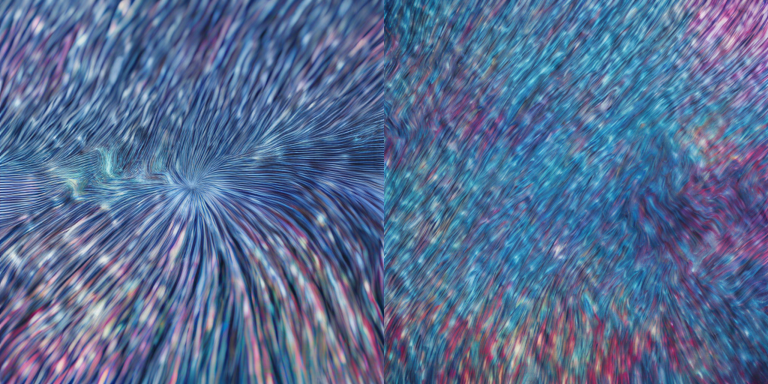

In [14]:
from PIL import Image
from IPython.display import display

c, k = (N - 1) // 6, (N - 1) % 6
a_cfg, b_cfg = M.settings(M.FACTORS[k], c)
full = [L.generate(pipe, cfg["prompt"], 101, steps=cfg["steps"], guidance=cfg["guidance"], size=cfg["size"])[0] for cfg in (a_cfg, b_cfg)]
pair = [im.resize((384, 384)) for im in full]
sheet = Image.new("RGB", (768, 384))
sheet.paste(pair[0], (0, 0)); sheet.paste(pair[1], (384, 0))
sheet.save(ART / "comparison.png")

rec101 = {r["mode"]: r for r in RECORDS if r["seed"] == 101}
REPRO_101 = {mode: L.sha(L.png_bytes(im)) == rec101[mode]["png_sha256"] for mode, im in zip("AB", full)}
print("Сохранено: LR06/artifacts/comparison.png")
print("Повторная генерация seed 101 совпала с серией бит в бит:", REPRO_101)
display(sheet)

Лист всей серии: сверху A=512, снизу B=768; seed 101–105 слева направо. Для поиска артефактов нужны также исходные изображения, сохранённые с манифестами.


series_seeds.png: верхний ряд A (512), нижний ряд B (768), seed 101…105 слева направо


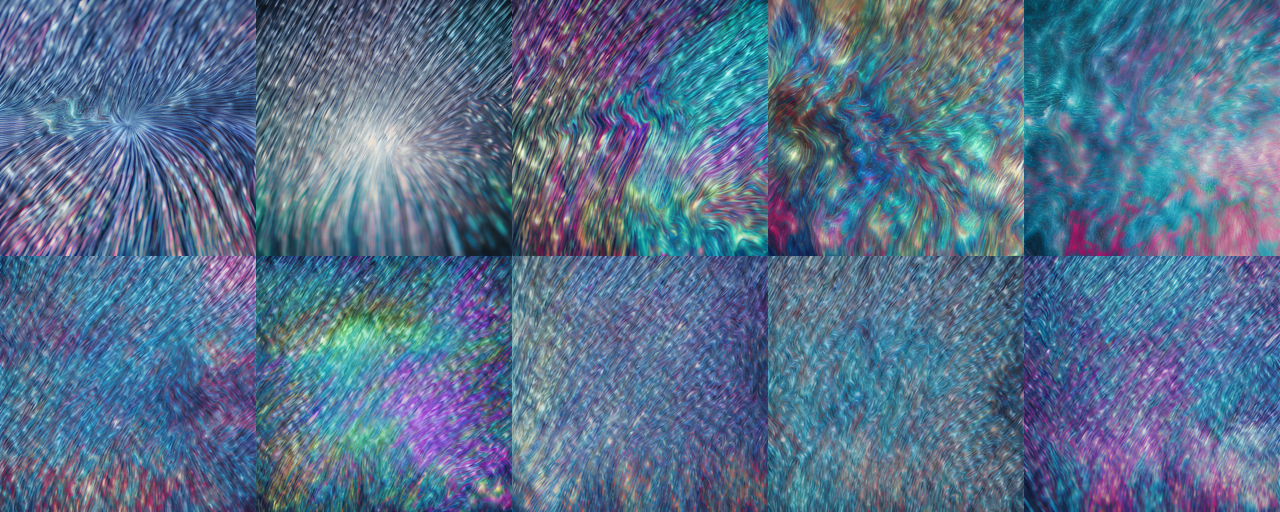

In [15]:
T = 256
grid = Image.new("RGB", (T * 5, T * 2), "white")
for r in RECORDS:
    grid.paste(r["img"].resize((T, T), Image.LANCZOS), ((r["seed"] - 101) * T, 0 if r["mode"] == "A" else T))
grid.save(ART / "series_seeds.png")
print("series_seeds.png: верхний ряд A (512), нижний ряд B (768), seed 101…105 слева направо")
display(grid)

### Контроль влияния масштаба

Энергия границ зависит от размера пикселя. Дополнительно сравниваются A и B на общем размере 512 и, контрольно, 768. Отдельно измеряется только интерполяция A: 512→768, без повторной генерации. Это диагностические проверки; основная таблица и допуски не подменяются ими.


In [16]:
def summarize(a_vals, b_vals):
    a_vals, b_vals = np.asarray(a_vals), np.asarray(b_vals)
    a, b, s = a_vals.mean(), b_vals.mean(), a_vals.std(ddof=1)
    delta = b - a
    return dict(A=float(a), s=float(s), B=float(b), delta=float(delta), delta_rel_pct=float(100 * delta / a),
                ratio=float(abs(delta) / s) if s > 0 else None, sig_2s=bool(abs(delta) > 2 * s))

imgs = {mode: [r["img"] for r in sorted(RECORDS, key=lambda r: r["seed"]) if r["mode"] == mode] for mode in "AB"}
B512 = [im.resize((512, 512), Image.LANCZOS) for im in imgs["B"]]
A768 = [im.resize((768, 768), Image.LANCZOS) for im in imgs["A"]]
COMMON = {}
for metric, fn in (("edge", M.edge_energy), ("contrast", M.contrast)):
    COMMON[f"{metric}@512"] = summarize([fn(x) for x in imgs["A"]], [fn(x) for x in B512])
    COMMON[f"{metric}@768"] = summarize([fn(x) for x in A768], [fn(x) for x in imgs["B"]])
COMMON["edge: только масштаб A 512 -> A 768"] = summarize([M.edge_energy(x) for x in imgs["A"]], [M.edge_energy(x) for x in A768])
for name, row in COMMON.items():
    row["verdict"] = verdict(name.split("@")[0], row["A"], row["delta"]) if "@" in name else "не классифицируется"
    print(name, row)


edge@512 {'A': 0.03532255799396396, 's': 0.012309371373534656, 'B': 0.034939291566132825, 'delta': -0.0003832664278311318, 'delta_rel_pct': -1.0850472038197962, 'ratio': 0.03113614954011061, 'sig_2s': False, 'verdict': 'нейтрально'}
edge@768 {'A': 0.029429225336215014, 's': 0.009506703289947736, 'B': 0.030544189137529088, 'delta': 0.0011149638013140742, 'delta_rel_pct': 3.7886277622877897, 'ratio': 0.1172818554769688, 'sig_2s': False, 'verdict': 'нейтрально'}
contrast@512 {'A': 0.13451651547728843, 's': 0.019872759878483078, 'B': 0.1061422368132054, 'delta': -0.028374278664083027, 'delta_rel_pct': -21.093527856714143, 'ratio': 1.4277975901477498, 'sig_2s': False, 'verdict': 'ухудшение'}
contrast@768 {'A': 0.13433012226335167, 's': 0.01986543315600696, 'B': 0.10766201744610895, 'delta': -0.026668104817242716, 'delta_rel_pct': -19.852661761864848, 'ratio': 1.342437620554916, 'sig_2s': False, 'verdict': 'ухудшение'}
edge: только масштаб A 512 -> A 768 {'A': 0.03532255799396396, 's': 0.012

## 9. Допуск и критерий 2s

Ожидание, превышение разброса базы и практическая классификация выводятся раздельно. Несогласие критериев сохраняется как результат.


In [17]:
DISAGREE = []
print(f"{'метрика':15s} {'гипотеза':28s} {'|Δ|>2s':>7s} {'допуск':>12s}  согласие 2s и допуска")
for r in ROWS:
    out_tol = r["verdict"] != "нейтрально"
    agree = out_tol == r["sig_2s"]
    note = "согласны" if agree else ("значимо по 2s, но в допуске" if r["sig_2s"] else "вне допуска, но не значимо по 2s")
    if not agree:
        DISAGREE.append(dict(metric=r["metric"], note=note))
    r["agree_2s_tol"] = agree
    print(f"{NAMES[r['metric']]:15s} {HYPOTHESIS[r['metric']]:28.28s} {'да' if r['sig_2s'] else 'нет':>7s} {r['verdict']:>12s}  {note}")
print("\nРасхождения критерия 2s и допуска:", DISAGREE if DISAGREE else "нет")

метрика         гипотеза                      |Δ|>2s       допуск  согласие 2s и допуска
сходство CLIP   нейтрально                       нет   нейтрально  согласны
энергия границ  снижение >10 % на исходном р     нет    ухудшение  вне допуска, но не значимо по 2s
контраст        нейтрально                       нет    ухудшение  вне допуска, но не значимо по 2s
время, с        ухудшение (рост >20 %)            да    ухудшение  согласны

Расхождения критерия 2s и допуска: [{'metric': 'edge', 'note': 'вне допуска, но не значимо по 2s'}, {'metric': 'contrast', 'note': 'вне допуска, но не значимо по 2s'}]


Чувствительность проверяется при допуске ×0,5, ×1 и ×2. Основной допуск остаётся прежним; порог не подгоняется под полученные изображения.


In [18]:
SENS = {}
print(f"{'метрика':15s} {'допуск ×0,5':>13s} {'×1':>13s} {'×2':>13s}  порог смены ответа")
for r in ROWS:
    m = r["metric"]
    kind, tol = TOL[m]
    vs = {x: verdict(m, r["A"], r["delta"], x) for x in (0.5, 1.0, 2.0)}
    flip = abs(r["delta"]) if kind == "abs" else abs(r["delta"] / r["A"])
    SENS[m] = dict(half=vs[0.5], base=vs[1.0], double=vs[2.0], flip_threshold=flip, flip_in_units_of_tol=flip / tol)
    thr = f"{flip:.2f} (CLIP)" if kind == "abs" else f"{100 * flip:.1f} %"
    print(f"{NAMES[m]:15s} {vs[0.5]:>13s} {vs[1.0]:>13s} {vs[2.0]:>13s}  {thr} = {flip / tol:.2f} допуска")

метрика           допуск ×0,5            ×1            ×2  порог смены ответа
сходство CLIP      нейтрально    нейтрально    нейтрально  0.42 (CLIP) = 0.42 допуска
энергия границ      ухудшение     ухудшение    нейтрально  13.5 % = 1.35 допуска
контраст            ухудшение     ухудшение    нейтрально  20.0 % = 2.00 допуска
время, с            ухудшение     ухудшение     ухудшение  114.7 % = 5.74 допуска


## 10. Намеренная ошибка: guidance=1

На своём брифе проверяется ожидание, что guidance_scale=1 включает CFG. Сравниваются SHA при 0 и 1 и состояние do_classifier_free_guidance; затем проверяется 3, выходящее за рекомендованный режим. Результат не переносится автоматически на другие модели.


In [19]:
# Намеренная ошибка: ожидание, что guidance_scale = 1.0 «включает» guidance у SD Turbo.
p = L.BRIEFS[c]
x0 = L.generate(pipe, p, 101, guidance=0.0)[0]
x1 = L.generate(pipe, p, 101, guidance=1.0)[0]
print("guidance 1.0: результат совпал с guidance 0.0 бит в бит:", L.sha(L.png_bytes(x0)) == L.sha(L.png_bytes(x1)), "| CFG активен:", pipe.do_classifier_free_guidance)
cfg_at_1 = pipe.do_classifier_free_guidance
x3 = L.generate(pipe, p, 101, guidance=3.0)[0]
print("guidance 3.0: CFG активен:", pipe.do_classifier_free_guidance, "| PSNR относительно guidance 0.0, дБ:", round(L.psnr_db(x0, x3), 2))
GUIDANCE = dict(sha_equal_0_vs_1=L.sha(L.png_bytes(x0)) == L.sha(L.png_bytes(x1)), cfg_at_1=cfg_at_1,
                cfg_at_3=pipe.do_classifier_free_guidance, psnr_0_vs_3_db=round(L.psnr_db(x0, x3), 2),
                sha_x0=L.sha(L.png_bytes(x0)))
GUIDANCE["x0_equals_series_A_seed101"] = GUIDANCE["sha_x0"] == rec101["A"]["png_sha256"]
print("x0 (бриф 5, seed 101, 512, guidance 0) совпадает с изображением A seed 101 из серии:", GUIDANCE["x0_equals_series_A_seed101"])

guidance 1.0: результат совпал с guidance 0.0 бит в бит: True | CFG активен: False
guidance 3.0: CFG активен: True | PSNR относительно guidance 0.0, дБ: 10.61
x0 (бриф 5, seed 101, 512, guidance 0) совпадает с изображением A seed 101 из серии: True


## 11. Сопоставление с демонстрационным вариантом 1

Это отдельный бриф 1 и изменение шагов 1→4. Таблица сопоставляется с методическими указаниями; совпадение не предполагается заранее. Время зависит от оборудования и загрузки GPU.


In [20]:
DEMO_REF = {  # раздел 6.3 указаний: A, s, B, Δ, |Δ|/s, |Δ| > 2s
    "clip": (30.796, 1.394, 30.292, -0.504, 0.36, False),
    "edge": (0.0457, 0.0069, 0.0920, +0.0463, 6.68, True),
    "contrast": (0.1923, 0.0226, 0.2778, +0.0855, 3.79, True),
    "seconds": (0.2854, 0.0027, 0.5266, +0.2412, 87.77, True),
}
t0 = time.perf_counter()
res1 = M.variant_summary(pipe, clip, 1)
t_demo = time.perf_counter() - t0
print("Вариант", res1["variant"], "фактор", res1["factor"], f"| {t_demo:.1f} с")
for m, a, s, b, d, ratio, sig in res1["rows"]:
    print(f"{m:9s} A={a:.4f} s={s:.4f} B={b:.4f} d={d:+.4f} |d|/s={ratio:.2f} 2s={'да' if sig else 'нет'}")

DEMO_CMP = []
print(f"\n{'метрика':15s} {'A указ.':>8s} {'A здесь':>8s} {'расх. A':>8s} {'B указ.':>8s} {'B здесь':>8s} {'расх. B':>8s}  2s указ./здесь  допуск указ./здесь")
for m, a, s, b, d, ratio, sig in res1["rows"]:
    ra, rs, rb, rd, rr, rsig = DEMO_REF[m]
    v_ref, v_here = [("в допуске" if verdict(m, x, y) == "нейтрально" else "вне допуска") for x, y in ((ra, rd), (a, d))]
    row = dict(metric=m, A_ref=ra, A=a, B_ref=rb, B=b, sig_ref=rsig, sig=sig, verdict_ref=v_ref, verdict=v_here)
    if m == "seconds":
        row.update(ratio_BA_ref=rb / ra, ratio_BA=b / a)
        dev_a, dev_b = f"B/A {rb / ra:.2f}", f"B/A {b / a:.2f}"
    else:
        row.update(dev_A_pct=100 * (a - ra) / ra, dev_B_pct=100 * (b - rb) / rb)
        dev_a, dev_b = f"{row['dev_A_pct']:+.1f} %", f"{row['dev_B_pct']:+.1f} %"
    row["conclusion_match"] = (rsig == sig) and (v_ref == v_here)
    DEMO_CMP.append(row)
    print(f"{NAMES[m]:15s} {ra:8.4f} {a:8.4f} {dev_a:>8s} {rb:8.4f} {b:8.4f} {dev_b:>8s}  {'да' if rsig else 'нет':>5s}/{'да' if sig else 'нет':<4s}  {v_ref:>11s}/{v_here}")
print("\nВыводы демонстрационного варианта воспроизведены по всем метрикам:", all(r["conclusion_match"] for r in DEMO_CMP))

Вариант 1 фактор steps_1_to_4 | 5.3 с
clip      A=30.7979 s=1.4309 B=30.2920 d=-0.5059 |d|/s=0.35 2s=нет
edge      A=0.0457 s=0.0070 B=0.0920 d=+0.0463 |d|/s=6.65 2s=да
contrast  A=0.1923 s=0.0225 B=0.2779 d=+0.0856 |d|/s=3.80 2s=да
seconds   A=0.2854 s=0.0019 B=0.5270 d=+0.2415 |d|/s=130.06 2s=да

метрика          A указ.  A здесь  расх. A  B указ.  B здесь  расх. B  2s указ./здесь  допуск указ./здесь
сходство CLIP    30.7960  30.7979   +0.0 %  30.2920  30.2920   +0.0 %    нет/нет     в допуске/в допуске
энергия границ    0.0457   0.0457   -0.1 %   0.0920   0.0920   -0.0 %     да/да    вне допуска/вне допуска
контраст          0.1923   0.1923   -0.0 %   0.2778   0.2779   +0.0 %     да/да    вне допуска/вне допуска
время, с          0.2854   0.2854 B/A 1.85   0.5266   0.5270 B/A 1.85     да/да    вне допуска/вне допуска

Выводы демонстрационного варианта воспроизведены по всем метрикам: True


### Демонстрационный скрипт преподавателя

lab06_demo.py выполняется без изменения текста. Он использует бриф 1; его результаты сохраняются отдельно от своего варианта в итоговом JSON. Основные модели предварительно освобождаются, чтобы не держать две копии на GPU.


In [21]:
%%writefile lab06_demo.py
# ЛР 6, демонстрационный вариант 1: бриф «афиша фестиваля робототехники» × число шагов (1 → 4), серия seed 101…105.
import lab05_lib as L
import lab06_lib as M

pipe = L.load_pipe()
clip = M.load_clip()
res = M.variant_summary(pipe, clip, 1)
print("Вариант", res["variant"], "фактор", res["factor"])
for m, a, s, b, d, ratio, sig in res["rows"]:
    print(f"{m:9s} A={a:.4f} s={s:.4f} B={b:.4f} d={d:+.4f} |d|/s={ratio:.2f} 2s={'да' if sig else 'нет'}")

# Намеренная ошибка: ожидание, что guidance_scale = 1.0 «включает» guidance у SD Turbo.
p = L.BRIEFS[0]
x0 = L.generate(pipe, p, 101, guidance=0.0)[0]
x1 = L.generate(pipe, p, 101, guidance=1.0)[0]
print("guidance 1.0: результат совпал с guidance 0.0 бит в бит:", L.sha(L.png_bytes(x0)) == L.sha(L.png_bytes(x1)), "| CFG активен:", pipe.do_classifier_free_guidance)
x3 = L.generate(pipe, p, 101, guidance=3.0)[0]
print("guidance 3.0: CFG активен:", pipe.do_classifier_free_guidance, "| PSNR относительно guidance 0.0, дБ:", round(L.psnr_db(x0, x3), 2))


Writing lab06_demo.py


In [22]:
import runpy, gc
DEMO = WORK / "demo"
DEMO.mkdir(exist_ok=True)
del pipe, clip
gc.collect()
torch.cuda.empty_cache()
os.chdir(DEMO)
try:
    demo_scope = runpy.run_path(str(WORK / "lab06_demo.py"), run_name="__main__")
finally:
    os.chdir(WORK)
DEMO_SCRIPT = dict(summary=demo_scope["res"],
                   sha_equal_guidance_0_vs_1=L.sha(L.png_bytes(demo_scope["x0"])) == L.sha(L.png_bytes(demo_scope["x1"])),
                   psnr_guidance_0_vs_3=L.psnr_db(demo_scope["x0"], demo_scope["x3"]))
del demo_scope
gc.collect()
torch.cuda.empty_cache()


Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Вариант 1 фактор steps_1_to_4
clip      A=30.7979 s=1.4309 B=30.2920 d=-0.5059 |d|/s=0.35 2s=нет
edge      A=0.0457 s=0.0070 B=0.0920 d=+0.0463 |d|/s=6.65 2s=да
contrast  A=0.1923 s=0.0225 B=0.2779 d=+0.0856 |d|/s=3.80 2s=да
seconds   A=0.2891 s=0.0019 B=0.5336 d=+0.2445 |d|/s=128.87 2s=да
guidance 1.0: результат совпал с guidance 0.0 бит в бит: True | CFG активен: False
guidance 3.0: CFG активен: True | PSNR относительно guidance 0.0, дБ: 11.61


## 12. Сохранение результатов

results.json включает полные ревизии обеих моделей, среду, параметры, значения каждого seed, сводку, контроль масштаба, допуски, проверку guidance и демонстрационные проверки. Исходные изображения хранятся с манифестами.


In [23]:
import json
from datetime import datetime, timezone

RESULTS = dict(
    lab="ЛР 6. Исследование параметров text-to-image генерации", author="Котов Дэвид Арсенович", variant=N,
    date_utc=datetime.now(timezone.utc).isoformat(), brief=L.BRIEFS[c], factor=M.FACTORS[k],
    model_id=L.MODEL_ID, revision=L.REVISION, clip_model_id=M.CLIP_ID, clip_revision=M.CLIP_REVISION,
    settings_A=a_cfg, settings_B=b_cfg, seeds=list(M.SEEDS), environment=ENV, load=LOAD, library_sha256=LIB_SHA,
    tolerance=TOL, hypothesis=HYPOTHESIS, rows=ROWS, common_scale=COMMON, sensitivity=SENS,
    per_seed=[{key: value for key, value in r.items() if key != "img"} for r in RECORDS],
    criterion_disagreements=DISAGREE, repeat_seed101=REPRO_101, guidance_error=GUIDANCE,
    demonstration=res1, demonstration_comparison=DEMO_CMP, demonstration_script=DEMO_SCRIPT,
    series_seconds=t_series)
(ART / "results.json").write_text(json.dumps(RESULTS, ensure_ascii=False, indent=2), encoding="utf-8")
print("Сохранено: LR06/artifacts/results.json")


Сохранено: LR06/artifacts/results.json


## Визуальная оценка

Верхний ряд листа серии — A=512, нижний — B=768; seed 101–105 слева направо. Просмотрены также все десять исходных кадров.

| Seed | A, 512×512 | B, 768×768 |
| --- | --- | --- |
| 101 | Чёткий веер тонких штрихов с центром около середины; холодные синие и серебристые оттенки. | Более равномерная синяя фактура; несколько центров завихрения вместо одного фокуса. |
| 102 | Светлый серебристый центр и тёмная рамка фактуры по краям. | Яркие зелёные и пурпурные области, множество волнообразных направлений; прежний светлый центр не сохраняется. |
| 103 | Насыщенные бирюзовые и пурпурные изгибы. | Преимущественно серебристо-синяя диагональная фактура; цветовые акценты слабее. |
| 104 | Разноцветные волны и завитки по всему кадру. | Более холодная синяя фактура с повторяющимися извилистыми полосами. |
| 105 | Мягкие бирюзовые и розовые световые пятна, структура местами размыта. | Более заметные диагональные штрихи и крупные завитки; композиция и распределение цвета иные. |

На всех кадрах главный элемент — блестящая радужная штриховая фактура. Узнаваемость именно металла неоднозначна: рисунок напоминает также волокна. Явных людей, текста и логотипов не видно. Композиция меняется во всех пяти парах. Повторяющиеся волны есть в обоих режимах; явных пустых участков и геометрических разрывов не обнаружено. Поэтому новый класс видимых артефактов, присущий только 768, не установлен. Увеличение размера не сделало материал однозначно более реалистичным.


## Ограничения

Одна модель, один бриф и пять seed ограничивают переносимость вывода. Размер меняет не только число пикселей, но и форму начального шума, поэтому композиция при одном seed может отличаться. Метрики деталей зависят от масштаба; интерполяционные контроли не заменяют исходную серию. CLIP — сходство с текстом в своём представлении, а не оценка эстетики. Время зависит от GPU и порядка выполнения A/B. Предсказанные артефакты считаются обнаруженными только после просмотра исходных изображений.


## 13. Контрольные суммы и выгрузка

Контрольные суммы всех результатов записываются в SHA256SUMS. ZIP содержит папку artifacts с исходными кадрами, манифестами, сравнительными листами и итоговым JSON. Выводы ячеек сохраняются в самом блокноте.


In [24]:
import zipfile
from google.colab import files

lines = []
for path in sorted(ART.rglob("*")):
    if path.is_file() and path.name != "SHA256SUMS":
        relative = path.relative_to(ART).as_posix()
        digest = hashlib.sha256(path.read_bytes()).hexdigest()
        lines.append(f"{digest}  {relative}")
        print(f"{digest}  {path.stat().st_size:9d}  {relative}")
(ART / "SHA256SUMS").write_text("\n".join(lines) + "\n", encoding="utf-8")
archive = WORK.parent / "LR06_results.zip"
with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as z:
    for path in sorted(ART.rglob("*")):
        if path.is_file():
            z.write(path, path.relative_to(WORK).as_posix())
print(f"Общее время: {(time.perf_counter() - T_START) / 60:.1f} мин")
print("Архив: LR06_results.zip")
files.download(str(archive))


93b4a1ff1c1dc1420edc7bedab21b82ed31229bced6aeac247f7d37558da077e     617424  comparison.png
e5a418cdd317951b599478fdb40cc96b08d0ff56d3621e05d1147b59a2ae92d0      13940  results.json
6c74ee359ce57827d84ff0b1ba0a2aa246b04c9566df786307a2df9314cbd219       1950  series/A_seed101/manifest.json
d41f2c83f6c305e8714b7ae13f0047274218a407ff375c2916092a5059c0f614     531014  series/A_seed101/result.png
1d5d2f4298abad824b90f6bd9bbc758a3e66144e41ba71e964b5872aa062d33e       1948  series/A_seed102/manifest.json
0dd89d0891241593b29f789cca374840534eeecf633791d3bdc1b94831f906a0     495814  series/A_seed102/result.png
d1ad508e58676d51d2e8928de9cb413cfd756eb38debab0a2fdca3ea73079f97       1951  series/A_seed103/manifest.json
7a3e3832fee45d0f5c4426c740a8a3b0a48a9c2b856c0c4fcb84c6f2600496d6     526285  series/A_seed103/result.png
d7d0474720370c9c4ae1f61c9aab9ba371644f14c76ceb3f544364c1227c4897       1949  series/A_seed104/manifest.json
2953a430c9704890291713c7950360591434eac3ca4647a77535c3e3afa54de4     49

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Итог

Время выросло с 0,3070 до 0,6593 с (+114,746 %). CLIP изменился на +0,4245 — в допуске ±1,0. Энергия границ снизилась на 13,528 %, контраст — на 19,964 %: оба отклика вне основного допуска, но не превышают 2s. На общем масштабе изменение энергии границ небольшое (−1,085 % при 512 и +3,789 % при 768), а снижение контраста сохраняется.

Гипотеза подтвердилась по CLIP, энергии границ и времени; ожидание неизменного контраста не подтвердилось. Новый класс видимых артефактов только у 768 не установлен. Более высокий размер в этой серии не дал практически важного выигрыша CLIP и увеличил стоимость генерации. Это вывод об одной модели, брифе и пяти seed, а не общая оценка качества изображений 768×768.
